# MSFT Monthly Returns and Macroeconomic Drivers

## Objective

Build one validated monthly analytical dataset for **January 2021 through August 2026** and use that same dataset for EDA, correlation, OLS regression, diagnostics, and conditional scenario analysis.

The model is descriptive and conditional. Statistical association is not interpreted as causal certainty or guaranteed predictive performance.

## Pipeline

`RAW DATA -> schema audit -> frequency alignment -> month key -> merge -> completeness gate -> feature engineering -> frozen analytical dataset -> EDA -> correlation -> OLS -> diagnostics -> prediction -> scenarios -> limitations`

## Data sources

- **MSFT:** Yahoo Finance daily OHLCV; adjusted close is used for return construction.
- **FEDFUNDS, CPIAUCSL, UNRATE:** FRED monthly observations.
- **DGS10:** FRED daily 10-year Treasury yield, converted to monthly mean.
- **SP500:** FRED daily S&P 500 close, converted to month-end level.
- **Buffer:** December 2020 MSFT/SP500 data and January 2020 CPI are used only to construct January 2021 lagged features.

## Formulae

Monthly MSFT and S&P 500 log returns:

$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right) \times 100$$

Year-over-year inflation:

$$Inflation_t = \frac{CPI_t - CPI_{t-12}}{CPI_{t-12}} \times 100$$

OLS specification:

$$MSFT\_Return_t = \beta_0 + \beta_1 FEDFUNDS_t + \beta_2 DGS10_t + \beta_3 Inflation_t + \beta_4 UNRATE_t + \beta_5 SP500\_Return_t + \epsilon_t$$

Residual and fit measures:

$$e_t = y_t - \hat{y}_t, \qquad R^2 = 1 - \frac{\sum e_t^2}{\sum (y_t - \bar{y})^2}$$

$$Adjusted\ R^2 = 1 - (1-R^2)\frac{n-1}{n-k-1}$$

For a new input row, the confidence interval describes the expected mean response; the prediction interval describes one future observation and is wider.


In [9]:
from __future__ import annotations

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

MAIN_DIR = ROOT / "data" / "main"
BUFFER_DIR = ROOT / "data" / "buffe"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

REPORT_START = pd.Period("2021-01", freq="M")
REPORT_END = pd.Period("2026-08", freq="M")
EXPECTED_MONTHS = pd.period_range(REPORT_START, REPORT_END, freq="M")
assert len(EXPECTED_MONTHS) == 68

print(f"Python: {sys.version.split()[0]}")
print(f"Root: {ROOT}")
print(f"Reporting window: {REPORT_START} to {REPORT_END} ({len(EXPECTED_MONTHS)} months)")


Python: 3.12.10
Root: d:\CODE\BI\BTVN3
Reporting window: 2021-01 to 2026-08 (68 months)


In [10]:
def load_yahoo_csv(path: Path, value_name: str = "Adj Close") -> pd.DataFrame:
    """Read yfinance's two metadata rows and return a clean daily table."""
    raw = pd.read_csv(path, header=0, skiprows=[1, 2])
    raw = raw.rename(columns={raw.columns[0]: "date"})
    raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
    raw = raw.dropna(subset=["date"]).set_index("date").sort_index()
    raw = raw[~raw.index.duplicated(keep="last")]
    for column in raw.columns:
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    if value_name not in raw.columns:
        raise KeyError(f"{value_name!r} not found in {path.name}: {list(raw.columns)}")
    return raw


def load_fred_excel(path: Path, value_name: str) -> pd.DataFrame:
    """Read the data sheet (last sheet) from a FRED Excel export."""
    workbook = pd.ExcelFile(path)
    frame = pd.read_excel(path, sheet_name=workbook.sheet_names[-1])
    frame = frame.rename(columns={frame.columns[0]: "date", frame.columns[1]: value_name})
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame[value_name] = pd.to_numeric(frame[value_name], errors="coerce")
    frame = frame.dropna(subset=["date"]).set_index("date").sort_index()
    if frame.index.duplicated().any():
        raise ValueError(f"Duplicate dates found in {path.name}")
    return frame[[value_name]]


def audit_frame(name: str, frame: pd.DataFrame, role: str) -> dict:
    return {
        "source": name,
        "role": role,
        "first_date": frame.index.min(),
        "last_date": frame.index.max(),
        "rows": len(frame),
        "duplicate_dates": int(frame.index.duplicated().sum()),
        "missing_values": int(frame.isna().sum().sum()),
    }


msft_main = load_yahoo_csv(MAIN_DIR / "MSFT_daily_2021-01-01_2026-08-01.csv")
msft_buffer = load_yahoo_csv(BUFFER_DIR / "MSFT_daily_2020-12-01_2020-12-31.csv")
msft = pd.concat([msft_buffer, msft_main]).sort_index()
msft = msft[~msft.index.duplicated(keep="last")]

cpi_main = load_fred_excel(MAIN_DIR / "CPIAUCSL.xlsx", "CPI")
cpi_buffer = load_fred_excel(BUFFER_DIR / "CPIAUCSL (1).xlsx", "CPI")
cpi = pd.concat([cpi_buffer, cpi_main]).sort_index()
cpi = cpi[~cpi.index.duplicated(keep="last")]

sp500_main = load_fred_excel(MAIN_DIR / "SP500.xlsx", "SP500")
sp500_buffer = load_fred_excel(BUFFER_DIR / "SP500 (2).xlsx", "SP500")
sp500 = pd.concat([sp500_buffer, sp500_main]).sort_index()
sp500 = sp500[~sp500.index.duplicated(keep="last")]

dgs10 = load_fred_excel(MAIN_DIR / "DGS10.xlsx", "DGS10")
fedfunds = load_fred_excel(MAIN_DIR / "FEDFUNDS.xlsx", "FEDFUNDS")
unrate = load_fred_excel(MAIN_DIR / "UNRATE.xlsx", "UNRATE")

audit = pd.DataFrame([
    audit_frame("MSFT", msft, "main + buffer"),
    audit_frame("CPI", cpi, "main + buffer"),
    audit_frame("SP500", sp500, "main + buffer"),
    audit_frame("DGS10", dgs10, "main"),
    audit_frame("FEDFUNDS", fedfunds, "main"),
    audit_frame("UNRATE", unrate, "main"),
])
display(audit)

assert msft_buffer.index.max().date().isoformat() == "2020-12-31"
assert cpi_buffer.index.min().to_period("M") <= pd.Period("2020-01", freq="M")
assert sp500_buffer.index.max().to_period("M") == pd.Period("2020-12", freq="M")


,source,role,first_date,last_date,rows,duplicate_dates,missing_values
0,MSFT,main + buffer,2020-12-01,2026-07-31,1422,0,0
1,CPI,main + buffer,2020-01-01,2026-08-01,69,0,1
2,SP500,main + buffer,2020-12-01,2026-07-31,1478,0,56
3,DGS10,main,2021-01-04,2026-07-31,1455,0,60
4,FEDFUNDS,main,2021-01-01,2026-08-01,68,0,0
5,UNRATE,main,2021-01-01,2026-08-01,68,0,1


In [11]:
import yfinance as yf


def refresh_fred(series_id: str, value_name: str) -> pd.DataFrame:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    frame = pd.read_csv(url)
    frame = frame.rename(columns={"observation_date": "date", series_id: value_name})
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame[value_name] = pd.to_numeric(frame[value_name], errors="coerce")
    return frame.dropna(subset=["date"]).set_index("date")[[value_name]].sort_index()


def refresh_yahoo(ticker: str, value_name: str, start: str = "2020-12-01", end: str = "2026-09-01") -> pd.DataFrame:
    downloaded = yf.download(ticker, start=start, end=end, interval="1d", auto_adjust=False, progress=False)
    if downloaded.empty:
        raise RuntimeError(f"No Yahoo data returned for {ticker}")
    if isinstance(downloaded.columns, pd.MultiIndex):
        downloaded.columns = downloaded.columns.get_level_values(0)
    downloaded.index = pd.to_datetime(downloaded.index).tz_localize(None)
    source_column = "Adj Close" if "Adj Close" in downloaded.columns else "Close"
    return downloaded[[source_column]].rename(columns={source_column: value_name}).dropna()


def clean_index(frame: pd.DataFrame) -> pd.DataFrame:
    clean = frame.dropna()
    return clean.loc[~clean.index.duplicated(keep="last")].sort_index()


# Refresh from official public endpoints when the local export is incomplete.
msft_online = refresh_yahoo("MSFT", "MSFT_Price")
sp500_online = refresh_yahoo("^GSPC", "SP500")
dgs10_online = refresh_fred("DGS10", "DGS10")
cpi_online = refresh_fred("CPIAUCSL", "CPI")
fedfunds_online = refresh_fred("FEDFUNDS", "FEDFUNDS")
unrate_online = refresh_fred("UNRATE", "UNRATE")

# Keep the local buffer policy, while using refreshed official observations for the report window.
msft = clean_index(pd.concat([msft_buffer[["Adj Close"]].rename(columns={"Adj Close": "MSFT_Price"}), msft_online]))
sp500 = clean_index(pd.concat([sp500_buffer, sp500_online]))
cpi = clean_index(pd.concat([cpi_buffer, cpi_online]))
dgs10, fedfunds, unrate = map(clean_index, (dgs10_online, fedfunds_online, unrate_online))

print("Refreshed coverage:")
for name, frame in {"MSFT": msft, "SP500": sp500, "CPI": cpi, "DGS10": dgs10, "FEDFUNDS": fedfunds, "UNRATE": unrate}.items():
    print(f"{name:10s} {frame.index.min().date()} -> {frame.index.max().date()} ({len(frame):,} rows)")


Refreshed coverage:
MSFT       2020-12-01 -> 2026-08-31 (1,443 rows)
SP500      2020-12-01 -> 2026-08-31 (1,443 rows)
CPI        1947-01-01 -> 2026-08-01 (955 rows)
DGS10      1962-01-02 -> 2026-09-21 (16,165 rows)
FEDFUNDS   1954-07-01 -> 2026-08-01 (866 rows)
UNRATE     1948-01-01 -> 2026-08-01 (943 rows)


In [12]:
def to_monthly_last(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    monthly = frame[column].resample("ME").last().to_frame(column)
    monthly.index = monthly.index.to_period("M")
    return monthly


def to_monthly_mean(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    monthly = frame[column].resample("ME").mean().to_frame(column)
    monthly.index = monthly.index.to_period("M")
    return monthly


def to_monthly_native(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    monthly = frame[[column]].copy()
    monthly.index = monthly.index.to_period("M")
    monthly = monthly.groupby(level=0).last()
    return monthly


monthly_msft = to_monthly_last(msft, "MSFT_Price")
monthly_sp500 = to_monthly_last(sp500, "SP500")
monthly_dgs10 = to_monthly_mean(dgs10, "DGS10")
monthly_cpi = to_monthly_native(cpi, "CPI")
monthly_fedfunds = to_monthly_native(fedfunds, "FEDFUNDS")
monthly_unrate = to_monthly_native(unrate, "UNRATE")

raw_monthly = (
    monthly_msft.join(monthly_sp500, how="outer")
    .join(monthly_dgs10, how="outer")
    .join(monthly_cpi, how="outer")
    .join(monthly_fedfunds, how="outer")
    .join(monthly_unrate, how="outer")
    .sort_index()
)

raw_report = raw_monthly.reindex(EXPECTED_MONTHS)
missing_report = pd.DataFrame({
    "expected_n": len(EXPECTED_MONTHS),
    "actual_n": [raw_report[column].notna().sum() for column in raw_report.columns],
    "missing_n": [raw_report[column].isna().sum() for column in raw_report.columns],
}, index=raw_report.columns)
print("Raw reporting-window completeness:")
display(missing_report)
print("Missing months by variable:")
for column in raw_report.columns:
    missing_months = raw_report.index[raw_report[column].isna()].astype(str).tolist()
    if missing_months:
        print(f"{column}: {missing_months}")

assert raw_report.index.equals(EXPECTED_MONTHS)
assert raw_report.index.is_unique


Raw reporting-window completeness:


,expected_n,actual_n,missing_n
MSFT_Price,68,68,0
SP500,68,68,0
DGS10,68,68,0
CPI,68,67,1
FEDFUNDS,68,68,0
UNRATE,68,67,1


Missing months by variable:
CPI: ['2025-10']
UNRATE: ['2025-10']


## 1.0 Data validation gate

The reporting calendar contains 68 expected months. Official FRED data has no observation for `2025-10` for either `CPIAUCSL` or `UNRATE`, and the local exports show the same gap. Because the official observations cannot be recovered, this month is excluded explicitly after the raw audit. No forward-fill, interpolation, or silent `dropna()` is used.

The raw audit remains 68 months, while the complete analytical sample contains 67 months. This limitation is reported and carried through all downstream analysis.


In [14]:
required_raw = ["MSFT_Price", "SP500", "DGS10", "CPI", "FEDFUNDS", "UNRATE"]
missing_cells = raw_report[required_raw].isna().sum()
missing_cells = missing_cells[missing_cells > 0]
expected_missing = {
    "CPI": ["2025-10"],
    "UNRATE": ["2025-10"],
}
for column, expected_months in expected_missing.items():
    observed_months = raw_report.index[raw_report[column].isna()].astype(str).tolist()
    assert observed_months == expected_months, f"Unexpected missing months for {column}: {observed_months}"

excluded_months = pd.PeriodIndex(["2025-10"], freq="M")
analysis_months = EXPECTED_MONTHS.difference(excluded_months)
analysis_report = raw_report.loc[analysis_months, required_raw].copy()

assert len(raw_report) == 68
assert raw_report.index.is_unique
assert len(analysis_report) == 67
assert not analysis_report.isna().any().any()
print(f"Raw audit: {len(raw_report)} expected months")
print(f"Complete analytical sample: {len(analysis_report)} months")
print(f"Explicitly excluded official-gap month(s): {list(excluded_months.astype(str))}")


Raw audit: 68 expected months
Complete analytical sample: 67 months
Explicitly excluded official-gap month(s): ['2025-10']


## 1.1 Data sources and variables

### Raw variables

| Role | Variable | Symbol | Source | Raw frequency | Transformation |
|---|---|---|---|---|---|
| Dependent variable base | MSFT adjusted close | $P^{MSFT}$ | Yahoo Finance | Daily | Last trading-day value in each month |
| Predictor | Federal Funds Rate | $X_1$ | FRED: FEDFUNDS | Monthly | Native monthly value |
| Predictor | 10-Year Treasury Yield | $X_2$ | FRED: DGS10 | Daily | Monthly arithmetic mean |
| Predictor base | CPI index | $CPI$ | FRED: CPIAUCSL | Monthly | Used to calculate YoY inflation |
| Predictor | Unemployment Rate | $X_4$ | FRED: UNRATE | Monthly | Native monthly value |
| Predictor base | S&P 500 index | $P^{SP500}$ | FRED/Yahoo benchmark | Daily | Last trading-day value in each month |

### Derived model variables

- $Y = MSFT\_Return$: monthly MSFT log return in percent.
- $X_1 = FEDFUNDS$: federal funds rate in percent.
- $X_2 = DGS10$: monthly mean 10-year Treasury yield in percent.
- $X_3 = Inflation$: CPI year-over-year growth in percent.
- $X_4 = UNRATE$: unemployment rate in percent.
- $X_5 = SP500\_Return$: monthly S&P 500 log return in percent.

The reporting window is January 2021 to August 2026. The raw audit contains 68 calendar months; the complete model sample contains 67 months because official CPI and UNRATE observations are unavailable for October 2025.


In [15]:
## Feature engineering after the completeness gate
analytical = analysis_report.copy()
analytical["MSFT_Return"] = np.log(analytical["MSFT_Price"] / raw_monthly["MSFT_Price"].shift(1).reindex(analytical.index)) * 100
analytical["Inflation"] = (analytical["CPI"] / raw_monthly["CPI"].shift(12).reindex(analytical.index) - 1) * 100
analytical["SP500_Return"] = np.log(analytical["SP500"] / raw_monthly["SP500"].shift(1).reindex(analytical.index)) * 100

model_columns = ["MSFT_Return", "FEDFUNDS", "DGS10", "Inflation", "UNRATE", "SP500_Return"]
final_dataset = analytical[model_columns].copy()
assert len(final_dataset) == 67
assert final_dataset.index.is_unique
assert np.isfinite(final_dataset.to_numpy()).all()
assert not final_dataset.isna().any().any()

final_dataset.index.name = "month"
final_dataset.to_csv(ROOT / "data" / "analytical_dataset_monthly.csv")
display(final_dataset.head())


,MSFT_Return,FEDFUNDS,DGS10,Inflation,UNRATE,SP500_Return
month,,,,,,
2021-01,4.199759,0.09,1.081053,1.373844,6.4,-1.119914
2021-02,0.410953,0.08,1.257895,1.669817,6.2,2.575688
2021-03,1.448285,0.07,1.610870,2.667819,6.1,4.156281
2021-04,6.728622,0.07,1.635000,4.133077,6.1,5.109733
2021-05,-0.765651,0.06,1.621000,4.918257,5.8,0.547149


## 1.2 Thống kê mô tả và biểu đồ chuỗi thời gian

Bảng thống kê trình bày N, mean, median, standard deviation, minimum và maximum cho toàn bộ biến sử dụng trong mô hình. Các biểu đồ bên dưới dùng monthly frequency và trục thời gian hiển thị mỗi 6 tháng để dễ theo dõi xu hướng 2021–2026.


,N,Mean,Median,SD,Min,Max
MSFT_Return,67.0,1.302107,1.448285,7.492530,-18.814878,21.980307
FEDFUNDS,67.0,3.264328,4.100000,2.018530,0.060000,5.330000
DGS10,67.0,3.482201,4.020000,1.141553,1.081053,4.798095
Inflation,67.0,4.374520,3.353016,2.087800,1.373844,8.979361
UNRATE,67.0,4.189552,4.100000,0.710129,3.400000,6.400000
SP500_Return,67.0,1.035242,1.888696,4.380655,-9.804917,9.915133


d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


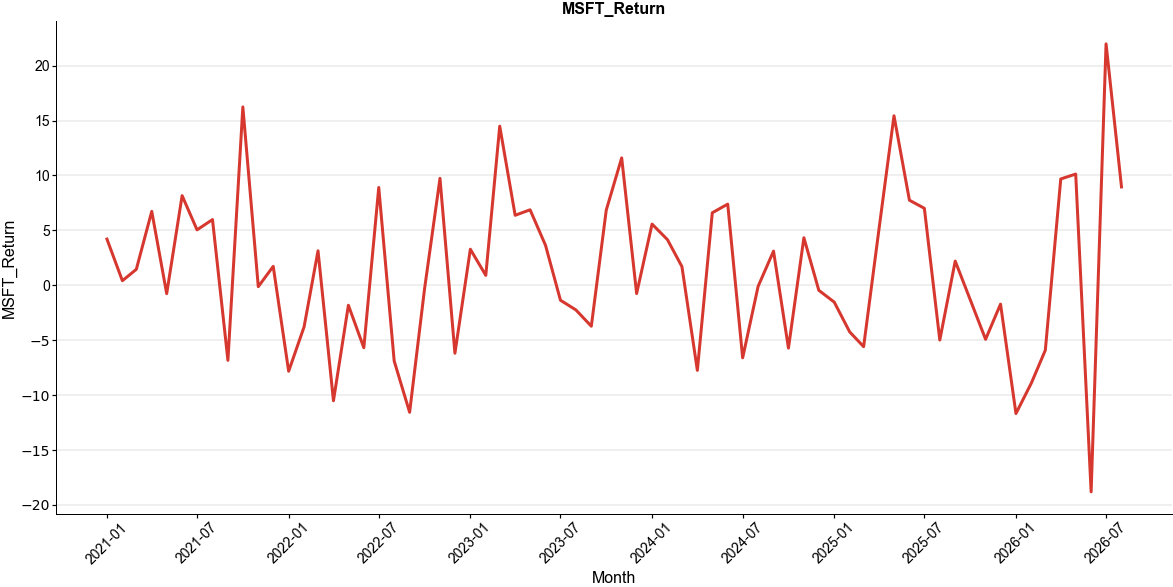

d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


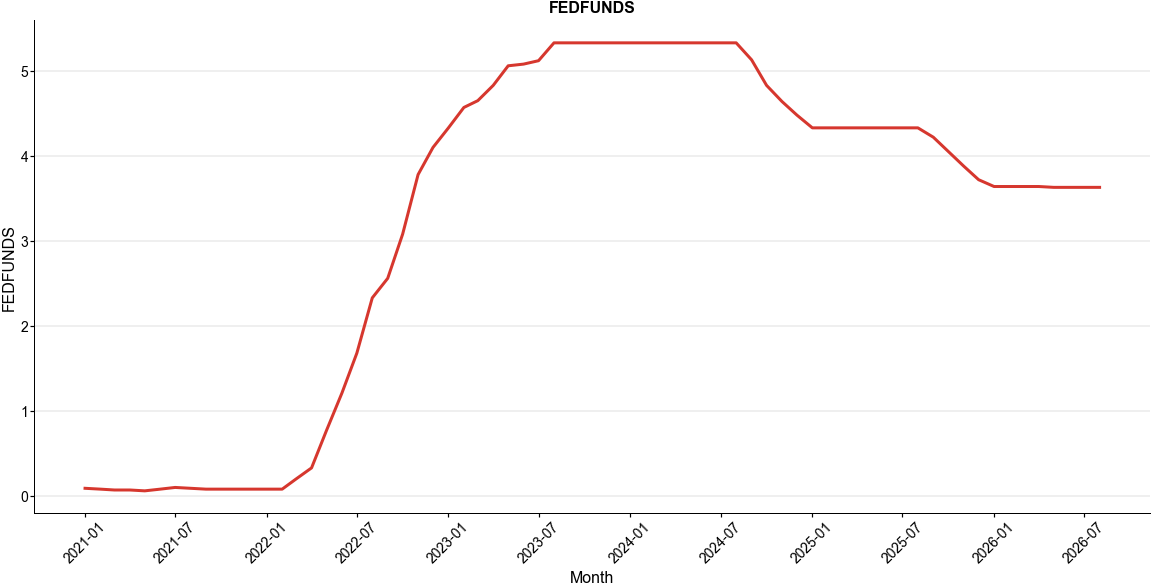

d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


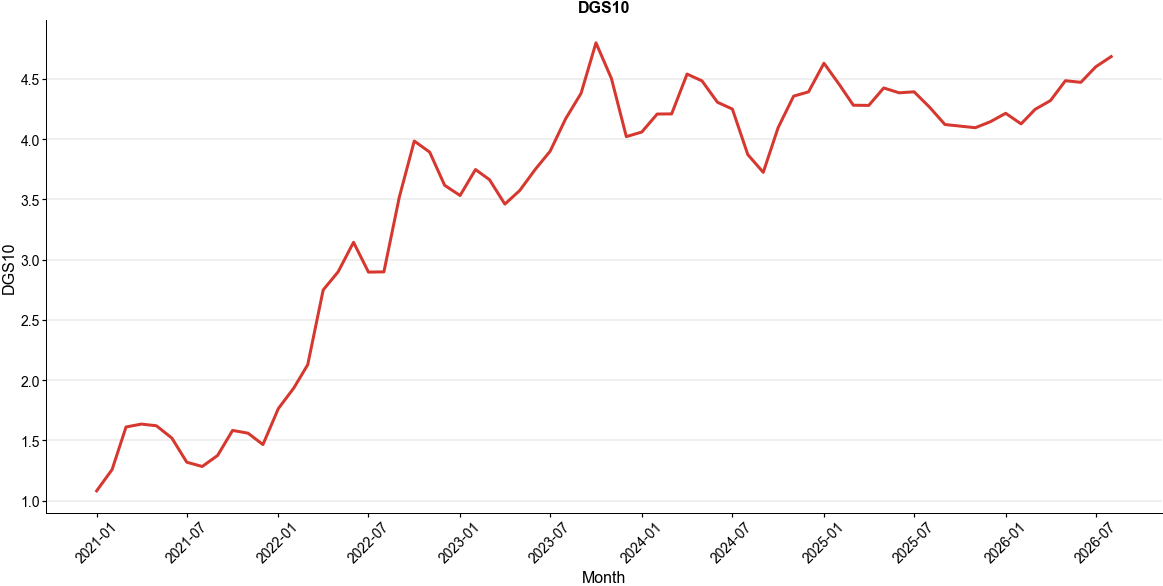

d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


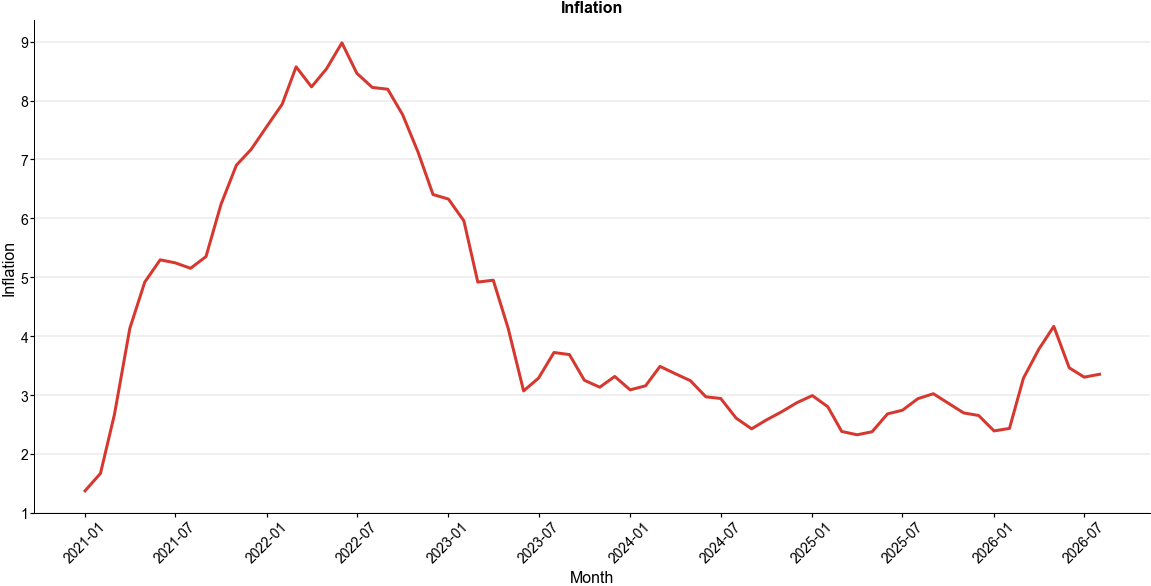

d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


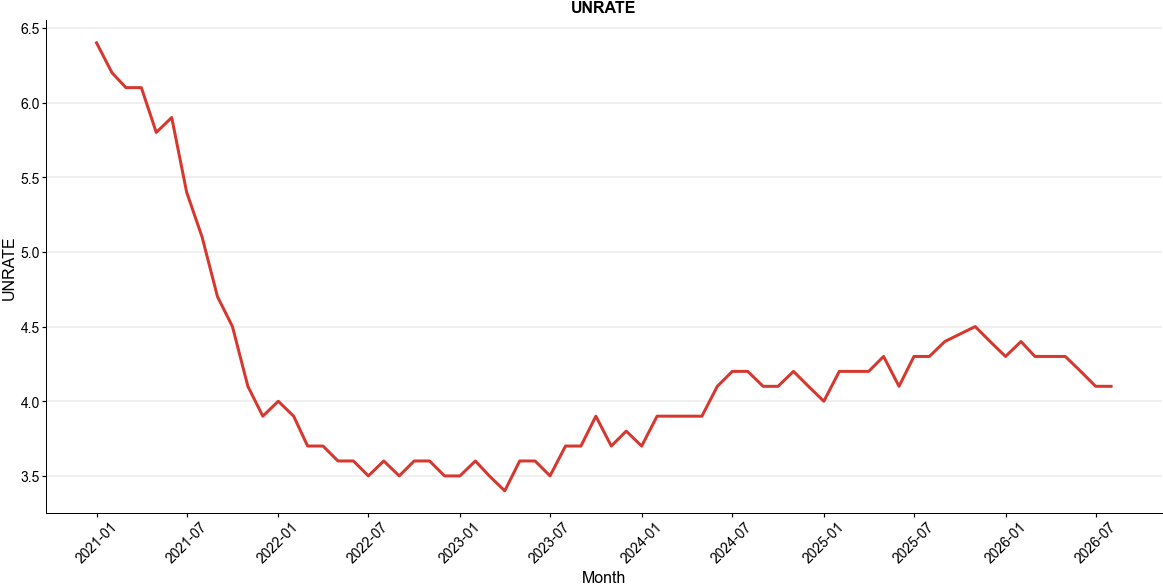

d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


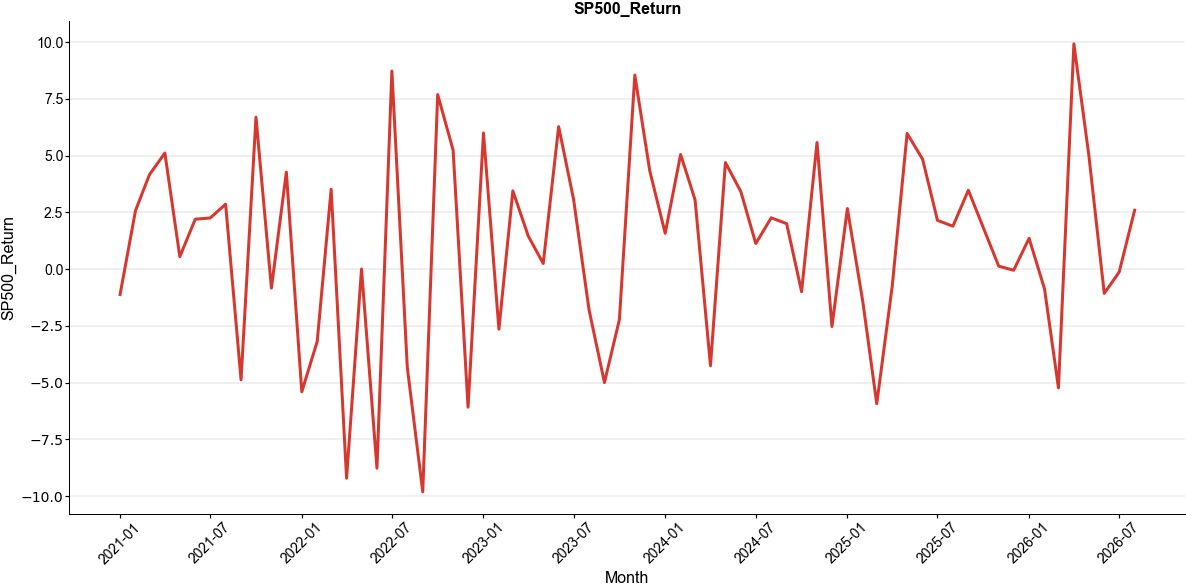

In [19]:
## 1.2 Descriptive statistics and time-series charts
import matplotlib.dates as mdates

summary = final_dataset.agg(["count", "mean", "median", "std", "min", "max"]).T
summary.columns = ["N", "Mean", "Median", "SD", "Min", "Max"]
display(summary)

plot_data = final_dataset.reset_index()
plot_data["month_date"] = plot_data["month"].dt.to_timestamp()
for column in model_columns:
    cns.figure(width=720, height=320)
    ax = cns.lineplot(data=plot_data, x="month_date", y=column, errorbar=None)
    ax.set(title=column, xlabel="Month", ylabel=column)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)
    cns.savefig(FIGURE_DIR / f"{column.lower()}_monthly.svg")
    plt.show()


## 1.3 Phân tích tương quan

Ma trận Pearson được tính trên cùng analytical dataset hoàn chỉnh. Mục tiêu là đánh giá sơ bộ quan hệ giữa MSFT Return và các biến giải thích, đồng thời nhận diện khả năng đa cộng tuyến giữa các predictor trước khi đọc VIF.


,MSFT_Return,FEDFUNDS,DGS10,Inflation,UNRATE,SP500_Return
MSFT_Return,1.000,0.061,0.001,-0.117,0.085,0.645
FEDFUNDS,0.061,1.000,0.905,-0.535,-0.535,0.127
DGS10,0.001,0.905,1.000,-0.444,-0.555,0.056
Inflation,-0.117,-0.535,-0.444,1.000,-0.348,-0.216
UNRATE,0.085,-0.535,-0.555,-0.348,1.000,0.112
SP500_Return,0.645,0.127,0.056,-0.216,0.112,1.000


d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


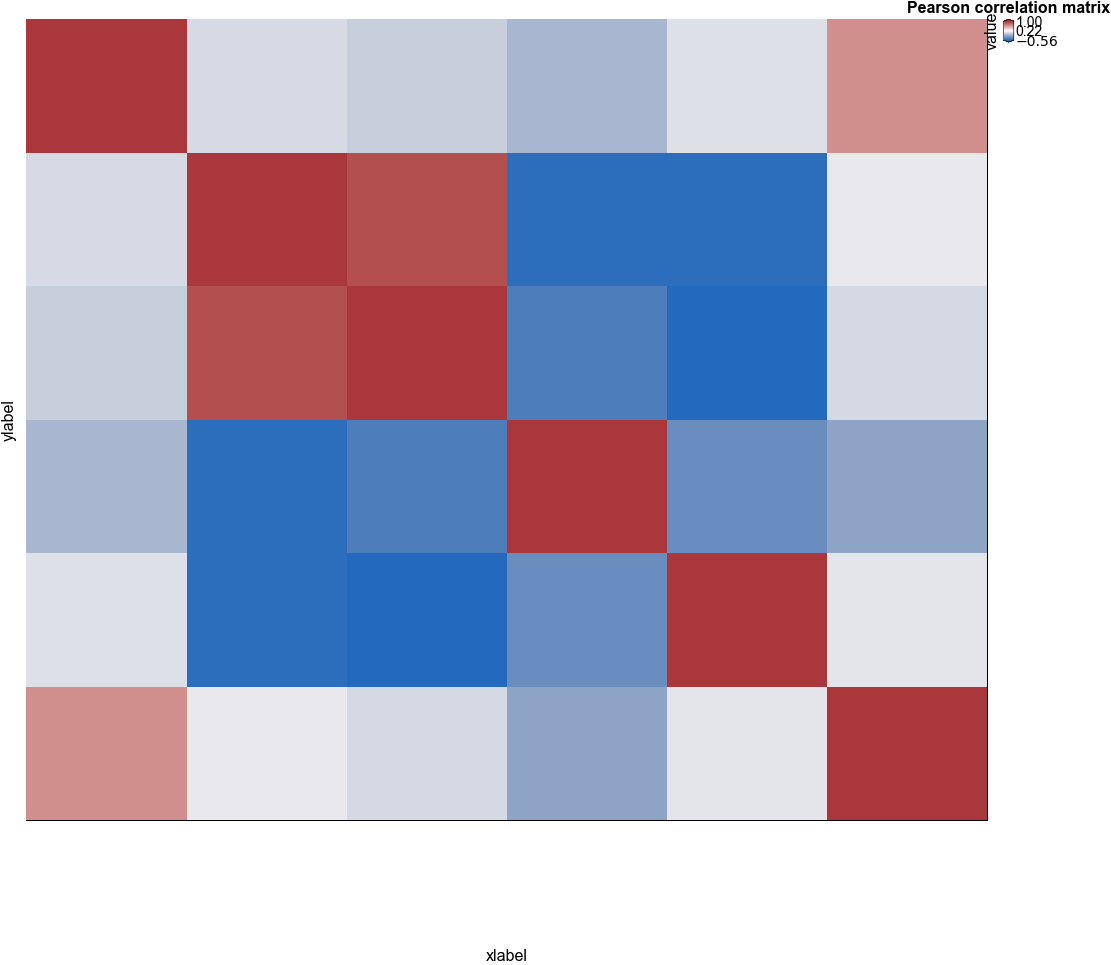

In [20]:
## 1.3 Correlation analysis

correlation_matrix = final_dataset.corr(method="pearson")
display(correlation_matrix.round(3))

cns.figure(width=620, height=520)
ax = cns.heatmapplot(correlation_matrix, cmap="vlag", xticklabels_rotation=45)
plt.title("Pearson correlation matrix")
cns.savefig(FIGURE_DIR / "correlation_heatmap.svg")
plt.show()


## PHẦN 2: ỨNG DỤNG MÔ HÌNH HỒI QUY

### 2.1 Đề xuất phương trình hồi quy

Mô hình hồi quy tuyến tính đa biến được đề xuất:

$$MSFT\_Return_t = \beta_0 + \beta_1FEDFUNDS_t + \beta_2DGS10_t + \beta_3Inflation_t + \beta_4UNRATE_t + \beta_5SP500\_Return_t + \varepsilon_t$$

Trong đó $Y = MSFT\_Return$ là lợi nhuận tháng của MSFT; $X_1$ đến $X_5$ là các biến lãi suất, lạm phát, thất nghiệp và lợi nhuận thị trường.

### 2.2 Kết quả hồi quy tổng thể và đa cộng tuyến

Bảng dưới đây trình bày hệ số ước lượng, sai số chuẩn, t-statistic, p-value và khoảng tin cậy 95%. VIF được dùng để kiểm tra mức độ trùng lặp thông tin giữa các biến độc lập; VIF cao là cảnh báo cần diễn giải thận trọng, không phải lý do tự động loại biến.


,Metric,Value
0,R-squared,0.419053
1,Adjusted R-squared,0.371435
2,RSE,5.940235
3,N,67.000000


,Coefficient,Std. Error,t,p-value,[0.025,0.975]
const,-3.206306,19.122984,-0.167668,8.673994e-01,-41.445076,35.032463
FEDFUNDS,0.464331,1.215352,0.382055,7.037484e-01,-1.965915,2.894577
DGS10,-0.543983,1.561752,-0.348316,7.288021e-01,-3.666900,2.578933
Inflation,0.259992,0.912522,0.284916,7.766735e-01,-1.564708,2.084693
UNRATE,0.623194,2.734908,0.227866,8.205122e-01,-4.845594,6.091981
SP500_Return,1.099935,0.173164,6.351974,2.970764e-08,0.753672,1.446199


,Variable,VIF,Tolerance
0,FEDFUNDS,11.256698,0.088836
1,DGS10,5.945014,0.168208
2,Inflation,6.788928,0.147299
3,UNRATE,7.054994,0.141744
4,SP500_Return,1.076296,0.929112


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17292\1584662013.py:25: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg = acorr_breusch_godfrey(model, nlags=1)


,Test,Statistic,p-value
0,Breusch-Pagan,10.429076,6.395134e-02
1,Breusch-Godfrey (1 lag),0.076616,7.819371e-01
2,Jarque-Bera,34.928919,2.601846e-08


d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


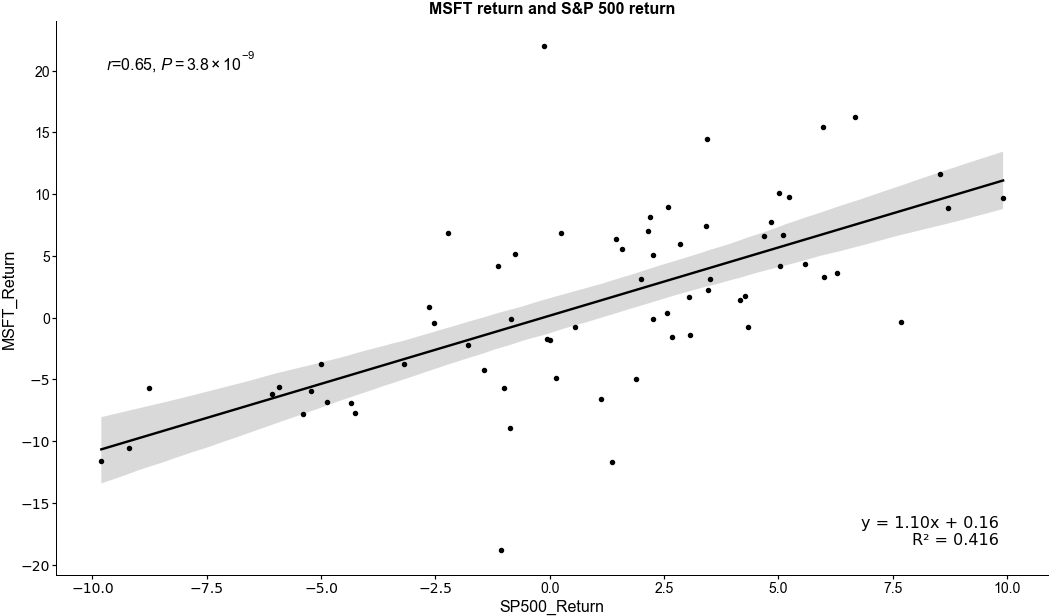

d:\python\Lib\site-packages\cnsplots\_svg.py:101: RuntimeWarning: MuPDF's `mutool` is unavailable; saved a standard matplotlib SVG instead.
  _save_plain_svg(


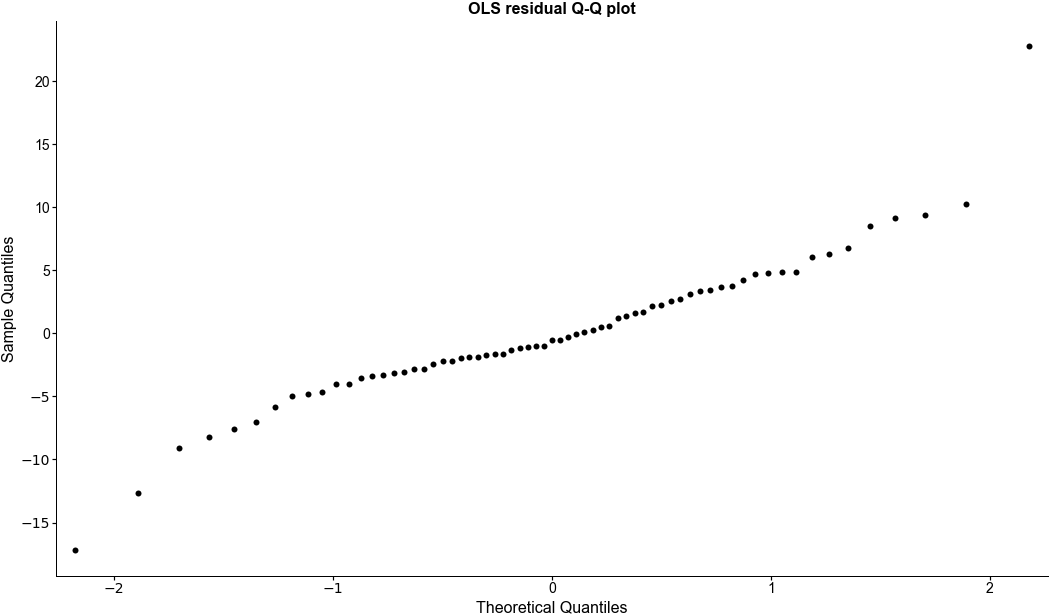

,FEDFUNDS,DGS10,Inflation,UNRATE,SP500_Return,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
Dovish,2.50,3.00,2.0,4.0,2.0,1.535201,-5.490193,8.560596,-12.265111,15.335514
Baseline,3.63,4.25,2.5,4.2,0.5,-0.015352,-3.378841,3.348137,-12.360615,12.329911
Hawkish,5.00,5.25,4.0,5.5,-2.0,-1.472900,-12.593237,9.647436,-17.744174,14.798373


In [21]:
## OLS, VIF, diagnostics, and scenario predictions
predictors = ["FEDFUNDS", "DGS10", "Inflation", "UNRATE", "SP500_Return"]
X = sm.add_constant(final_dataset[predictors])
y = final_dataset["MSFT_Return"]
model = sm.OLS(y, X).fit()

fit_metrics = pd.DataFrame({
    "Metric": ["R-squared", "Adjusted R-squared", "RSE", "N"],
    "Value": [model.rsquared, model.rsquared_adj, np.sqrt(model.mse_resid), int(model.nobs)],
})
display(fit_metrics)

regression_table = model.summary2().tables[1].copy()
regression_table = regression_table.rename(columns={"Coef.": "Coefficient", "Std.Err.": "Std. Error", "P>|t|": "p-value"})
display(regression_table)

vif_table = pd.DataFrame({
    "Variable": predictors,
    "VIF": [variance_inflation_factor(X[predictors].to_numpy(), i) for i in range(len(predictors))],
})
vif_table["Tolerance"] = 1 / vif_table["VIF"]
display(vif_table)

bp = het_breuschpagan(model.resid, model.model.exog)
bg = acorr_breusch_godfrey(model, nlags=1)
jb = stats.jarque_bera(model.resid)
diagnostics = pd.DataFrame([
    {"Test": "Breusch-Pagan", "Statistic": bp[0], "p-value": bp[1]},
    {"Test": "Breusch-Godfrey (1 lag)", "Statistic": bg[0], "p-value": bg[1]},
    {"Test": "Jarque-Bera", "Statistic": jb.statistic, "p-value": jb.pvalue},
])
display(diagnostics)

cns.figure(width=640, height=360)
ax = cns.regplot(data=plot_data, x="SP500_Return", y="MSFT_Return", add_equation=True)
ax.set(title="MSFT return and S&P 500 return")
cns.savefig(FIGURE_DIR / "msft_sp500_regression.svg")
plt.show()

cns.figure(width=640, height=360)
ax = cns.qqplot(pd.DataFrame({"residual": model.resid}), x="residual")
ax.set_title("OLS residual Q-Q plot")
cns.savefig(FIGURE_DIR / "ols_residual_qq.svg")
plt.show()

scenarios = pd.DataFrame({
    "FEDFUNDS": [2.50, 3.63, 5.00],
    "DGS10": [3.00, 4.25, 5.25],
    "Inflation": [2.00, 2.50, 4.00],
    "UNRATE": [4.00, 4.20, 5.50],
    "SP500_Return": [2.00, 0.50, -2.00],
}, index=["Dovish", "Baseline", "Hawkish"])
scenario_predictions = model.get_prediction(sm.add_constant(scenarios, has_constant="add")).summary_frame(alpha=0.05)
scenario_predictions = scenarios.join(scenario_predictions[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]])
display(scenario_predictions)


## 2.3 Chẩn đoán mô hình

Các kiểm định phần dư được tóm tắt ngắn gọn ở bảng trên:

- **Breusch–Pagan:** p-value khoảng 0.064, chưa có đủ bằng chứng ở mức 5% để kết luận phương sai thay đổi.
- **Breusch–Godfrey:** p-value khoảng 0.782, chưa phát hiện tự tương quan bậc một.
- **Jarque–Bera:** p-value rất nhỏ, cho thấy phần dư lệch khỏi phân phối chuẩn; cần thận trọng với suy luận trong mẫu nhỏ.
- **Q-Q plot:** được dùng để trực quan hóa độ lệch chuẩn của phần dư và các quan sát cực trị.

Kết luận chẩn đoán: mô hình không cho thấy bằng chứng rõ về heteroskedasticity hoặc autocorrelation ở các kiểm định trên, nhưng giả định normality của phần dư không được đáp ứng hoàn toàn. Vì vậy kết quả nên được xem là bằng chứng thực nghiệm có điều kiện, không phải chứng minh mô hình dự báo chắc chắn.

## PHẦN 3: ĐÁNH GIÁ MÔ HÌNH VÀ ỨNG DỤNG DỰ ĐOÁN

### 3.1 Ý nghĩa thống kê

Với từng biến độc lập, đọc đồng thời dấu của coefficient, độ lớn của t-statistic, p-value và khoảng tin cậy 95%:

- `SP500_Return` có coefficient dương khoảng 1.10 và p-value rất nhỏ, cho thấy mối liên hệ dương rõ nhất với MSFT Return trong mẫu.
- `FEDFUNDS`, `DGS10`, `Inflation` và `UNRATE` có p-value lớn hơn 0.05 trong mô hình hiện tại; chưa có đủ bằng chứng thống kê để khẳng định ảnh hưởng riêng biệt ở mức 5%.
- Kết luận trên là kết luận trong mẫu 67 tháng, không phải quan hệ nhân quả.

### 3.2 Độ chính xác và độ phù hợp

Báo cáo các chỉ tiêu từ `model`:

- **R²:** tỷ lệ biến thiên của MSFT Return được giải thích bởi năm biến độc lập trong mẫu.
- **Adjusted R²:** phiên bản đã điều chỉnh theo số predictor và kích thước mẫu; phù hợp hơn khi so sánh mô hình có số biến khác nhau.
- **RSE:** độ lệch chuẩn ước lượng của phần dư, biểu diễn quy mô sai số điển hình theo đơn vị phần trăm lợi nhuận tháng.

### 3.3 Khoảng dự đoán và kịch bản tương lai

Bảng scenario xác định đầy đủ $X_1$–$X_5$ cho ba trường hợp Dovish, Baseline và Hawkish. `mean_ci_lower/upper` là confidence interval cho lợi nhuận kỳ vọng; `obs_ci_lower/upper` là prediction interval cho một quan sát tương lai và rộng hơn.

Các kịch bản là phân tích what-if có điều kiện trên các giả định đầu vào, không phải dự báo chắc chắn các biến vĩ mô.

### 3.4 Giới hạn của mô hình

Đây là phần diễn giải quan trọng nhất. Dù một biến có t-statistic lớn, p-value nhỏ hoặc mô hình có R² tốt, độ rộng của prediction interval cho thấy lợi nhuận thực tế tương lai vẫn có bất định lớn. Ngoài ra, mô hình không biết trước chính xác FEDFUNDS, DGS10, Inflation, UNRATE và SP500 Return trong tương lai.

Mô hình còn bỏ sót các cú sốc riêng của MSFT như earnings, Azure, AI, định giá, sản phẩm, quản trị và tin tức bất ngờ. Quan hệ ước lượng trong giai đoạn 2021–2026 cũng có thể thay đổi khi regime kinh tế thay đổi. Vì vậy, statistical significance không đồng nghĩa với predictive certainty.

## KẾT LUẬN

Pipeline hoàn chỉnh là:

`Data -> EDA -> Correlation -> OLS -> Diagnostics -> Statistical significance -> Accuracy -> Prediction -> Scenarios -> Limitations`

Kết quả nên được trình bày như một phân tích định lượng có điều kiện về các yếu tố liên quan đến MSFT monthly return, không phải một hệ thống dự báo lợi nhuận chắc chắn.


## Interpretation and limitations

- Coefficients must be discussed using direction, magnitude, uncertainty, and economic context.
- Confidence intervals describe the expected mean response; prediction intervals describe one future observation and are wider.
- The model does not establish causality and may be affected by macro release timing, data revisions, and look-ahead bias.
- The 68-month sample is small for five predictors and may not represent future regimes.
- MSFT-specific earnings, Azure, AI, valuation, management, and unexpected company news are not fully captured.
- Future macro inputs are uncertain, so scenario results are conditional what-if calculations rather than guaranteed forecasts.

The notebook intentionally stops at the completeness gate while official `CPIAUCSL` and `UNRATE` remain missing for `2025-10`. No automatic fill or silent row deletion is permitted.
